## LAB 3 - TASK 2: supplementary longer run. Artificial Intelligence 2026-27.

**NAME AND NIP**: Jorge Ruiz (826685) and Hugo López (875455)

This notebook preserves the separate Colab experiment with 30 augmentation epochs and 40 larger-model epochs. The main Task 2 submission is `2_SimpleCNN.ipynb`.

### Description of the toy dataset:
* Number of classes: 5
* Classes: cheesecake, chicken_quesadilla, chicken_wings, churros, donuts
* Source: https://www.kaggle.com/kmader/food41/version/5
* Saved split: 4,000 training and 1,000 validation images (seed 123).


## Training from scratch

In this exercise we are building a small conv net to train from scratch using Tensorflow.Keras APIs

## Get data and tensorflow imports ready

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras import backend as K

import matplotlib.pyplot as plt

In [2]:
# GET YOUR IMAGES READY

# OPTION A: upload and unzip, untar ... images if necessary (not recommended ... it'll only last one session)
# from google.colab import files
# uploaded = files.upload()
# ## 'uploaded' is a dictionary. You can get the file content like this:
# for filename, content in uploaded.items():
#     print(f"Uploaded {filename} with {len(content)} bytes")
# ##!tar -xvzf images.tar.gz
# !unzip dataset.zip
# !ls

# OPTION B: mount your google drive to point the code to find the data in your drive folders
# (instructions here: https://colab.research.google.com/notebooks/io.ipynb#scrollTo=u22w3BFiOveA)
from google.colab import drive
drive.mount('/content/drive')
## Once mounted, you can access your drive at '/content/drive/MyDrive/'
## For example, if you have your toy-data.zip in a folder, you can run:
## !unzip "/content/drive/MyDrive/IA_p3_images/toy-data.zip" -d "/content/dataset"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Since you have the images in Google Drive subfolders, let's verify their existence
import os
drive_data_path = '/content/drive/MyDrive/IA_p3_images/'
if os.path.exists(drive_data_path):
    print("Found Google Drive image directory! Classes:")
    print(os.listdir(drive_data_path))
else:
    print(f"Could not find directory: {drive_data_path}. Please verify the path names inside '/content/drive/MyDrive/'.")

Found Google Drive image directory! Classes:
['cheesecake', 'chicken_quesadilla', 'chicken_wings', 'churros', 'donuts']


In [4]:
# SOME HELPER FUNCTIONS TO VISUALIZE RESULTS
def vis_history(results_history, epochs=10):
    acc = results_history.history['accuracy']
    val_acc = results_history.history['val_accuracy']

    loss = results_history.history['loss']
    val_loss = results_history.history['val_loss']

    epochs_range = range(epochs)

    plt.figure(figsize=(16, 8))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()



## Definning and training the CNN
You need to train 3 versions of this model:
* First run and train the model given here by default.
* Then evaluate what happens if you remove Dropout layer and train again.
* Then add code to incorporate image augmentation to the network training.

Use this example to see how to easily add data augmentation as an additional layer to your model. https://www.tensorflow.org/tutorials/images/classification#data_augmentation

Think what data augmentation could be interesting for your classes and program the layer to get it.

In [5]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if len(gpus) > 0:
    print(f"¡Sí! Se está detectando una GPU activa: {gpus}")
    # Display the active GPU name.
    !nvidia-smi --query-gpu=name --format=csv
else:
    print("No se detecta ninguna GPU activa en este entorno. El entrenamiento se está ejecutando en CPU (lento).")

¡Sí! Se está detectando una GPU activa: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
name
Tesla T4


In [6]:
# Completed starter exercise block.
# Dataset and training configuration.

# dimensions of our images.
img_width, img_height = 150, 150
# Dataset path configured above or in the mounted Drive.
# get and print the actual working directory to make sure you are pointing to the right place
import os
print("Current working directory:", os.getcwd())

data_dir = '/content/drive/MyDrive/IA_p3_images/' # pointing directly to your Google Drive folders
epochs = 10 # Training budget for this run.
batch_size = 4
num_classes = 5
# Completed starter exercise block.

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers

if K.image_data_format() == 'channels_first':
    input_shape = (3, img_width, img_height)
else:
    input_shape = (img_width, img_height, 3)

train_ds, val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="both",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# for more optimized handling of the data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

model = Sequential([
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.summary()

history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

model.save_weights('first_try.weights.h5')

Current working directory: /content
Found 5000 files belonging to 5 classes.
Using 4000 files for training.
Using 1000 files for validation.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,654,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,678,565 (10.22 MB)

 Trainable params: 2,678,565 (10.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 543s 197ms/step - accuracy: 0.3455 - loss: 1.4831 - val_accuracy: 0.4100 - val_loss: 1.4677
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4638 - loss: 1.3209 - val_accuracy: 0.4210 - val_loss: 1.3866
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5312 - loss: 1.1695 - val_accuracy: 0.4430 - val_loss: 1.3308
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6595 - loss: 0.8923 - val_accuracy: 0.4530 - val_loss: 1.4856
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7860 - loss: 0.5611 - val_accuracy: 0.4300 - val_loss: 1.9122
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9035 - loss: 0.2655 - val_accuracy: 0.4460 - val_loss: 2.7170
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9485 - loss: 0.1654 - val_accuracy: 0.4380 - val_loss: 3.5135
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9660 - loss: 0.09

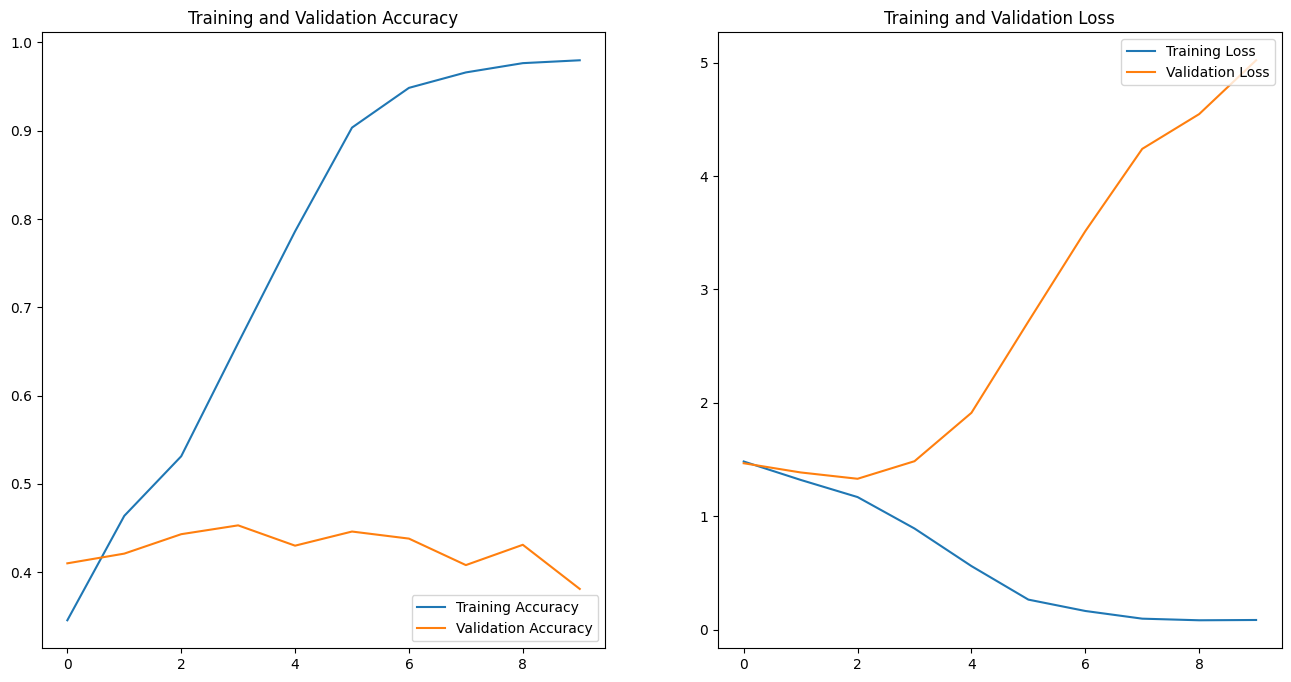

In [7]:
# VISUALIZE INITIAL RESULTS
import matplotlib.pyplot as plt
vis_history(history, 10)

The baseline overfits strongly. We add dropout to reduce the training-validation gap.


### Model 2

In [8]:
# Completed starter exercise block.
# Define, compile and train the model with dropout.
model2 = Sequential([
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),

  layers.Flatten(),

  # Dropout after Flatten reduces overfitting in the dense classifier.
  layers.Dropout(0.5),
  layers.Dense(128, activation='relu'),

  # A second dropout layer reduces co-adaptation before the output.
  layers.Dropout(0.5),
  layers.Dense(num_classes)
])

model2.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model2.summary()

history2 = model2.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

# Completed starter exercise block.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     2,654,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,678,565 (10.22 MB)

 Trainable params: 2,678,565 (10.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.3215 - loss: 1.5388 - val_accuracy: 0.4110 - val_loss: 1.4064
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.3983 - loss: 1.4286 - val_accuracy: 0.3860 - val_loss: 1.4324
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4467 - loss: 1.3468 - val_accuracy: 0.4040 - val_loss: 1.3745
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4807 - loss: 1.2796 - val_accuracy: 0.4350 - val_loss: 1.3172
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5180 - loss: 1.1986 - val_accuracy: 0.4520 - val_loss: 1.3147
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5617 - loss: 1.1172 - val_accuracy: 0.4630 - val_loss: 1.2895
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5935 - loss: 1.0358 - val_accuracy: 0.4450 - val_loss: 1.3579
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6320 - loss: 0.9494 -

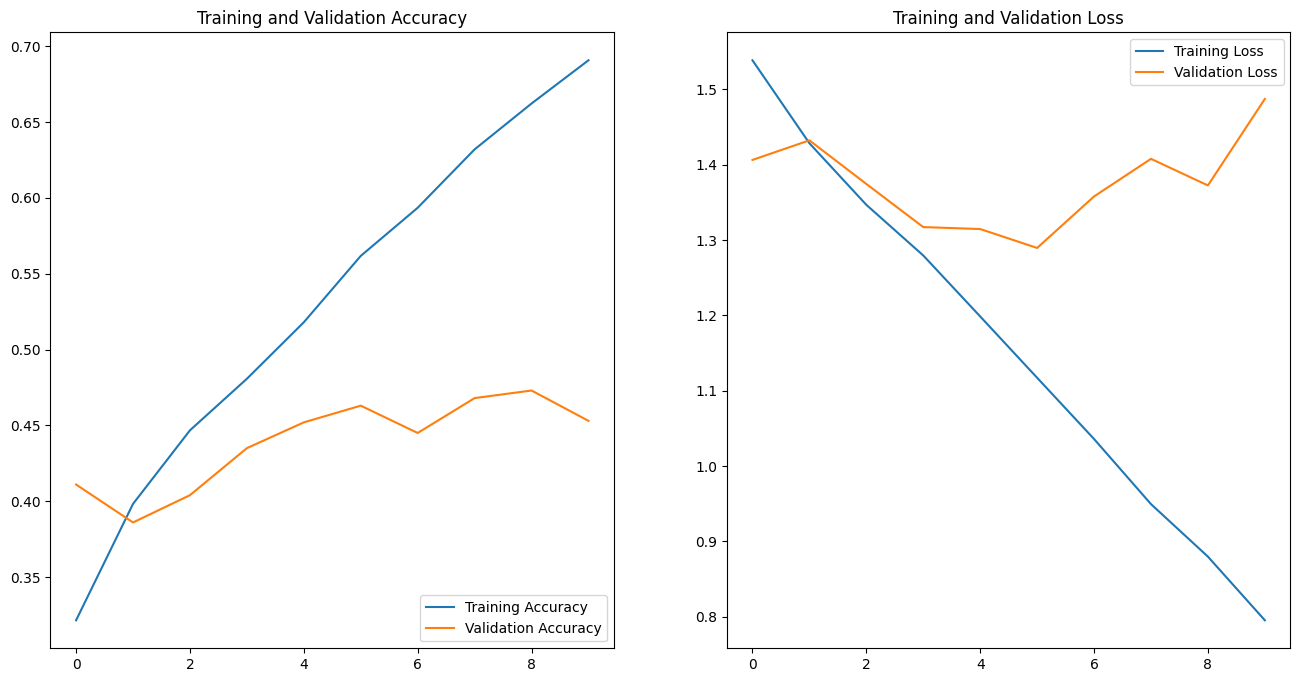

In [9]:
# VISUALIZE RESULTS WITH DROPOUT
vis_history(history2, epochs)

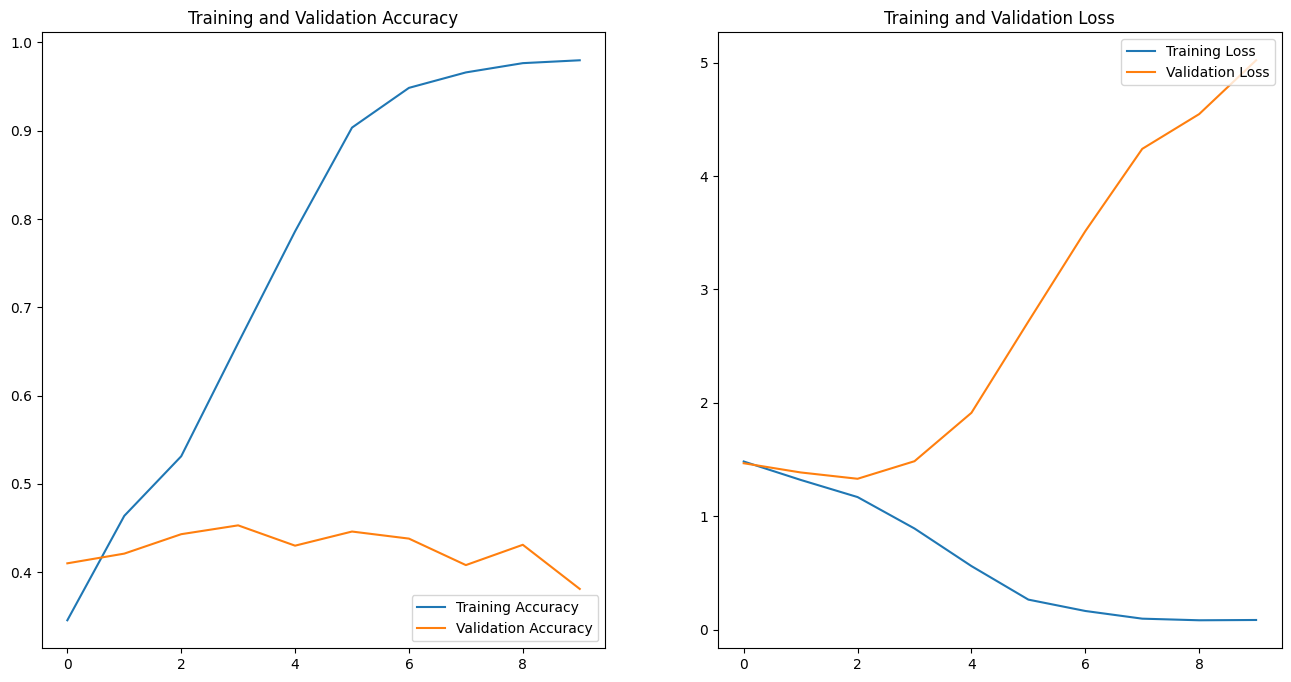

In [10]:
# PLOT HERE YOUR RESULTS WITHOUT DROPOUT
vis_history(history, epochs)

### Model 3

In [11]:
# Completed starter exercise block.
# Define, compile and train the model with dropout and augmentation.

data_augmentation = Sequential([
  layers.RandomFlip("horizontal"),
  layers.RandomRotation(0.15),
  layers.RandomZoom(0.1),
  layers.RandomContrast(0.1)
])

model3 = Sequential([
  data_augmentation,
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),

  layers.Flatten(),

  # Dropout after Flatten reduces overfitting in the dense classifier.
  layers.Dropout(0.5),
  layers.Dense(128, activation='relu'),

  # A second dropout layer reduces co-adaptation before the output.
  layers.Dropout(0.5),
  layers.Dense(num_classes)
])

model3.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model3.summary()

history3 = model3.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs+20
)
# Completed starter exercise block.


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.3007 - loss: 1.5397 - val_accuracy: 0.3660 - val_loss: 1.4637
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.3435 - loss: 1.4801 - val_accuracy: 0.3980 - val_loss: 1.4333
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.3835 - loss: 1.4475 - val_accuracy: 0.4360 - val_loss: 1.3728
Epoch 4/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.3913 - loss: 1.4193 - val_accuracy: 0.4450 - val_loss: 1.3298
Epoch 5/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.4140 - loss: 1.3855 - val_accuracy: 0.4560 - val_loss: 1.3166
Epoch 6/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.4310 - loss: 1.3504 - val_accuracy: 0.4530 - val_loss: 1.3059
Epoch 7/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.4385 - loss: 1.3586 - val_accuracy: 0.4780 - val_loss: 1.2922
Epoch 8/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.4467 - loss: 1.3

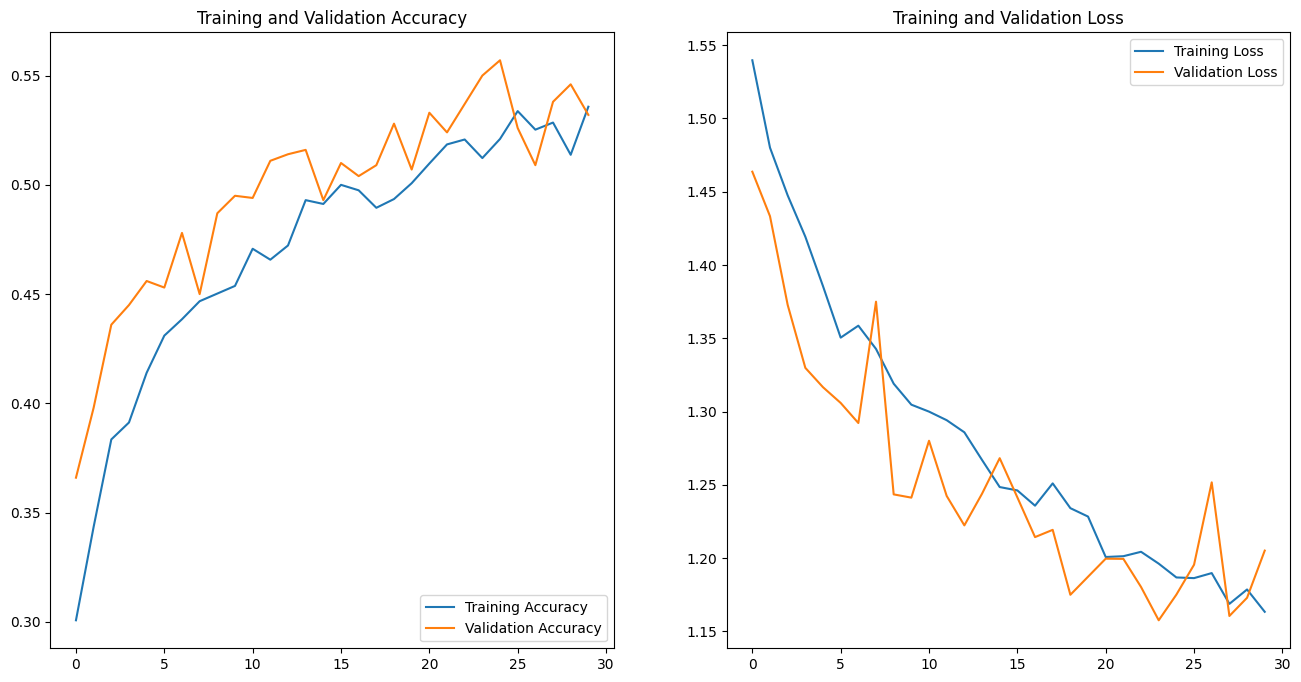

In [13]:
# PLOT HERE YOUR RESULTS INCLUDING DROPOUT and AUGMENTATION
import matplotlib.pyplot as plt
vis_history(history3, 30)

In [14]:
model4 = Sequential([
  data_augmentation,
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),

  # More filters in the first convolutional blocks.
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),

  # More filters in the deeper convolutional block.
  layers.Conv2D(128, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),

  layers.Flatten(),

  # Larger dense classifier with dropout.
  layers.Dropout(0.4),
  layers.Dense(256, activation='relu'), # Increase to 256 units.

  layers.Dropout(0.3),
  layers.Dense(num_classes)
])

model4.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model4.summary()

history4 = model4.fit(
  train_ds,
  validation_data=val_ds,
  epochs=40
)
# End of the larger-model experiment.

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │    10,617,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,711,621 (40.86 MB)

 Trainable params: 10,711,621 (40.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 18s 16ms/step - accuracy: 0.2862 - loss: 1.5474 - val_accuracy: 0.3050 - val_loss: 1.5245
Epoch 2/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.3755 - loss: 1.4556 - val_accuracy: 0.3370 - val_loss: 1.4871
Epoch 3/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.3870 - loss: 1.4137 - val_accuracy: 0.4120 - val_loss: 1.3902
Epoch 4/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.3957 - loss: 1.3796 - val_accuracy: 0.4400 - val_loss: 1.3428
Epoch 5/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.4275 - loss: 1.3506 - val_accuracy: 0.4410 - val_loss: 1.3356
Epoch 6/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.4392 - loss: 1.3208 - val_accuracy: 0.4730 - val_loss: 1.2904
Epoch 7/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.4635 - loss: 1.3013 - val_accuracy: 0.4730 - val_loss: 1.2805
Epoch 8/40
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.4697 -

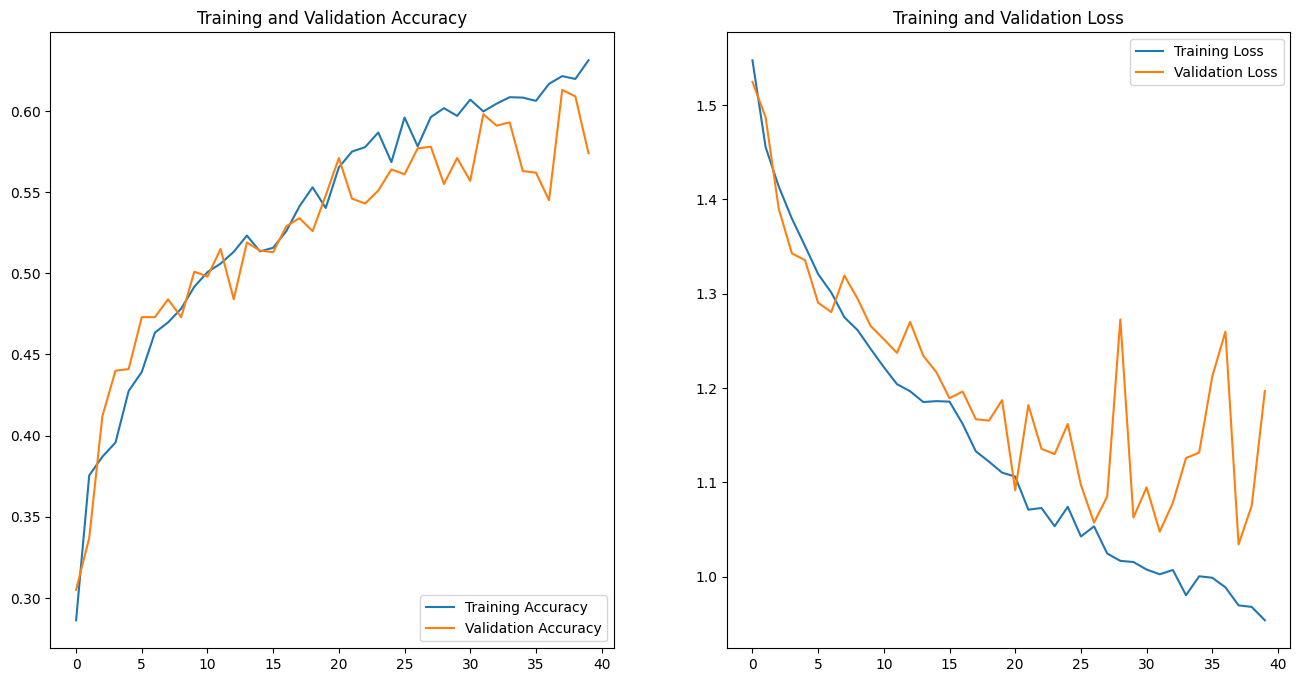

In [16]:
# VISUALIZE  RESULTS
vis_history(history4, 40)

### **QUESTION:** briefly discuss the results of the CNN with the different variations (with/without augmentation, with/without dropout). (maximum of 5 lines)

ANSWER:
The baseline ends at 97.97% training / 38.10% validation accuracy, showing severe overfitting.
Dropout reduces the gap to 69.08% / 45.30% after the same 10 epochs, but does not eliminate it.
Flips, rotations, zoom and contrast changes provide plausible variations of the food images.
The augmented model reaches 53.57% / 53.20% after 30 epochs; its budget differs from the 10-epoch baselines.
Dropout and augmentation make training harder, so similar training/validation accuracies do not alone establish underfitting.


Extra: The larger model uses more filters (32/64/128 instead of 16/32/64), 256 rather than 128 dense units, and dropout rates 0.4/0.3 rather than 0.5/0.5. All convolutional kernels remain 3x3. It reaches 63.13% training / 57.40% validation accuracy at epoch 40, with a peak validation accuracy of 61.30% at epoch 38. Capacity, dropout and training duration change together, so this does not isolate one factor or prove that a larger model is necessary.
